In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.multioutput import MultiOutputRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error, r2_score
import joblib
from statsmodels.tsa.arima.model import ARIMA
import warnings

from selenium import webdriver
from selenium.webdriver.chrome.service import Service
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
from selenium.webdriver.chrome.options import Options

warnings.filterwarnings('ignore')
np.random.seed(42)  # For reproducibility

In [2]:
# Path ke ChromeDriver
chrome_driver_path = "/Applications/MAMP/htdocs/local/kodingakademi/Python/python 3/final_ds/chromedriver-mac-arm64/chromedriver"

# Konfigurasi opsi Chrome
options = Options()
options.add_argument("--headless=new")  # Jalankan tanpa membuka jendela browser
options.add_argument("--disable-gpu")   # Mengurangi penggunaan GPU
options.add_argument("--no-sandbox")    # Untuk eksekusi di server tanpa GUI
options.add_argument("--disable-dev-shm-usage")  # Untuk menghindari error pada sistem berbasis Linux

# Inisialisasi WebDriver
service = Service(chrome_driver_path)
driver = webdriver.Chrome(service=service, options=options)

# Buka halaman Yahoo Finance
driver.get("https://finance.yahoo.com/quote/BBCA.JK/history/")

# Tunggu hingga tabel muncul
table = WebDriverWait(driver, 10).until(
    EC.presence_of_element_located((By.CLASS_NAME, "table"))
)

# Ambil semua baris tabel
rows = table.find_elements(By.TAG_NAME, "tr")

data = []
for row in rows:
    cols = row.find_elements(By.TAG_NAME, "td")
    if len(cols) == 7:
        date = cols[0].text 
        open = cols[1].text
        high = cols[2].text 
        low = cols[3].text  
        close = cols[4].text
        adj_close = cols[5].text  
        volume = cols[6].text  
        data.append([date, open, high, low, close, adj_close, volume])

# Simpan dalam DataFrame Pandas
df = pd.DataFrame(data, columns=["Date", "Open", "High", "Low", "Close", "Adj Close", "Volume"])

# Tutup browser
driver.quit()

In [3]:
# -------------------------
# 1. Preprocessing Data
# -------------------------
def preprocess_data(df_raw):
    df = df_raw.copy()
    df['Date'] = df['Date'].astype(str)
    df = df[df['Date'].str.match(r'^[A-Za-z]{3,} \d{1,2}, \d{4}$', na=False)]
    df['Date'] = pd.to_datetime(df['Date'], format='%b %d, %Y')
    cols = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
    for col in cols:
        df[col] = df[col].str.replace(',', '', regex=False).astype(float)
    df = df.sort_values('Date').reset_index(drop=True)
    return df

# -------------------------
# 1b. Tambahkan Indikator Teknikal
# -------------------------
def add_technical_indicators(df):
    df = df.copy()
    df['MA_5'] = df['Close'].rolling(window=5).mean()
    df['MA_10'] = df['Close'].rolling(window=10).mean()
    df['EMA_12'] = df['Close'].ewm(span=12, adjust=False).mean()
    df['EMA_26'] = df['Close'].ewm(span=26, adjust=False).mean()
    df['MACD'] = df['EMA_12'] - df['EMA_26']
    df['Momentum'] = df['Close'] - df['Close'].shift(1)
    df['Volatility_5'] = df['Close'].rolling(window=5).std()
    df['Price_Range'] = df['High'] - df['Low']
    # RSI
    delta = df['Close'].diff()
    gain = np.where(delta > 0, delta, 0)
    loss = np.where(delta < 0, -delta, 0)
    avg_gain = pd.Series(gain).rolling(window=14).mean()
    avg_loss = pd.Series(loss).rolling(window=14).mean()
    rs = avg_gain / (avg_loss + 1e-10)
    df['RSI'] = 100 - (100 / (1 + rs))
    df.dropna(inplace=True)
    return df

# -------------------------
# 2. Outlier Removal (IQR)
# Bisa digunakan untuk banyak kolom
# -------------------------
def remove_outliers_iqr(df, columns):
    df_out = df.copy()
    for column in columns:
        Q1 = df_out[column].quantile(0.25)
        Q3 = df_out[column].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        df_out = df_out[(df_out[column] >= lower) & (df_out[column] <= upper)]
    return df_out.reset_index(drop=True)

# -------------------------
# 3. Buat Multivariat Lag Features
# -------------------------
def create_multivariate_lag_features(df, target_cols, feature_cols, window):
    lagged_features = []
    for col in feature_cols:
        for i in range(1, window + 1):
            lagged_features.append(df[col].shift(i).rename(f'{col}_lag_{i}'))
    df_lag = pd.concat(lagged_features, axis=1)
    target_data = df[target_cols].copy()
    df_lag = pd.concat([df_lag, target_data], axis=1)
    df_lag.dropna(inplace=True)
    return df_lag

# -------------------------
# 4. Grid Search Lag dengan TimeSeriesSplit (scaling per fold)
# -------------------------
def grid_search_best_lag(df, target_cols, feature_cols, test_size=7, window_options=[i + 1 for i in range(20)]):
    df = df.reset_index(drop=True)
    df_train = df[:-test_size]
    results = []
    for window in window_options:
        df_ml = create_multivariate_lag_features(df_train, target_cols, feature_cols, window)
        if df_ml.shape[0] == 0:
            continue
        X = df_ml.drop(columns=target_cols)
        y = df_ml[target_cols]
        tscv = TimeSeriesSplit(n_splits=5)
        val_rmses = []
        for train_idx, val_idx in tscv.split(X):
            x_train, x_val = X.iloc[train_idx], X.iloc[val_idx]
            y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
            scaler_x = MinMaxScaler()
            scaler_y = MinMaxScaler()
            x_train_scaled = scaler_x.fit_transform(x_train)
            x_val_scaled = scaler_x.transform(x_val)
            y_train_scaled = scaler_y.fit_transform(y_train)
            y_val_scaled = scaler_y.transform(y_val)
            model = MultiOutputRegressor(XGBRegressor(
                objective='reg:squarederror',
                n_estimators=100,
                learning_rate=0.1,
                max_depth=5,
                subsample=0.8,
                colsample_bytree=0.8,
                random_state=42
            ))
            model.fit(x_train_scaled, y_train_scaled)
            y_pred_val = model.predict(x_val_scaled)
            rmse = np.sqrt(mean_squared_error(y_val_scaled, y_pred_val))
            val_rmses.append(rmse)
        avg_rmse = np.mean(val_rmses)
        results.append((window, avg_rmse))
    return results

# -------------------------
# 5. Plot RMSE per Window
# -------------------------
def plot_grid_results(results):
    windows, rmses = zip(*results)
    plt.figure(figsize=(10, 5))
    plt.plot(windows, rmses, marker='o')
    plt.title("Evaluasi Jumlah Lag berdasarkan TimeSeries RMSE")
    plt.xlabel("Jumlah Lag (window)")
    plt.ylabel("RMSE rata-rata")
    plt.xticks(windows)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# -------------------------
# 6. Forecast Future Function
# -------------------------
def forecast_future(model, df, scaler_x, scaler_y, target_cols, feature_cols, window, n_future):
    last_df = df[feature_cols].iloc[-window:].copy()
    forecast_scaled = []
    for _ in range(n_future):
        lag_data = {}
        for col in feature_cols:
            for i in range(1, window + 1):
                lag_data[f'{col}_lag_{i}'] = last_df[col].iloc[-i]
        input_df = pd.DataFrame([lag_data])
        input_scaled = scaler_x.transform(input_df)
        pred_scaled = model.predict(input_scaled)[0]
        pred_unscaled = scaler_y.inverse_transform([pred_scaled])[0]
        forecast_scaled.append(pred_unscaled)
        next_row = dict(zip(target_cols, pred_unscaled))
        last_df = pd.concat([last_df, pd.DataFrame([next_row])], ignore_index=True)
    return np.array(forecast_scaled)

# -------------------------
# 7. Visualize Forecast Function
# -------------------------
def visualize_forecast(df_clean, forecast, n_future=7, last_n_days=3, model_label='XGBoost'):
    last_n_dates = df_clean['Date'].iloc[-last_n_days:].tolist()
    last_n_close = df_clean['Close'].iloc[-last_n_days:].tolist()
    last_date = df_clean['Date'].iloc[-1]
    future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=n_future, freq='D').tolist()
    forecast_dates_full = [last_n_dates[-1]] + future_dates
    forecast_values_full = [last_n_close[-1]] + forecast[:, 0].tolist()
    all_dates = last_n_dates + future_dates
    plt.figure(figsize=(12, 5))
    plt.plot(last_n_dates, last_n_close, label=f'Actual (Last {last_n_days} Days)', linestyle='-', marker='o')
    plt.plot(forecast_dates_full, forecast_values_full, label=f'Forecast {model_label} (Next {n_future} Days)', linestyle='--', marker='o', color='orange')
    plt.axvspan(future_dates[0], future_dates[-1], color='orange', alpha=0.1, label='Forecast Area')
    all_y_values = last_n_close + forecast_values_full[1:]
    y_max = max(all_y_values)
    y_min = min(all_y_values)
    plt.ylim(y_min * 0.98, y_max * 1.05)
    for date, value in zip(last_n_dates, last_n_close):
        plt.text(date, value + y_max * 0.015, f'{value:.0f}', ha='center', va='bottom', fontsize=9)
    for date, value in zip(forecast_dates_full[1:], forecast_values_full[1:]):
        plt.text(date, value + y_max * 0.015, f'{value:.0f}', ha='center', va='bottom', fontsize=9, color='orange')
    plt.title(f'Close Price Forecasting: Last {last_n_days} Days + Next {n_future} Days ({model_label})')
    plt.xlabel('Date')
    plt.ylabel('Close Price')
    plt.legend()
    plt.xticks(ticks=all_dates, rotation=45)
    plt.tight_layout()
    plt.show()

# -------------------------
# 8. Feature Importance Plot
# -------------------------
def plot_feature_importance(model, feature_names, target_columns):
    for i, target in enumerate(target_columns):
        estimator = model.estimators_[i]
        importance = estimator.feature_importances_
        sorted_idx = importance.argsort()
        plt.figure(figsize=(10, 5))
        plt.barh(
            [feature_names[j] for j in sorted_idx],
            importance[sorted_idx]
        )
        plt.xlabel("Feature Importance")
        plt.title(f"Feature Importance for Predicting {target}")
        plt.tight_layout()
        plt.show()

# -------------------------
# 9. ARIMA Baseline
# -------------------------
def forecast_arima(df, n_future=7, last_n_days=3):
    # Only univariate Close
    model = ARIMA(df['Close'], order=(7, 1, 0))  # (p,d,q) p=lag window, d=1 differencing
    fit = model.fit()
    forecast = fit.forecast(steps=n_future)
    # Plot ARIMA baseline
    visualize_forecast(df, forecast.values.reshape(-1, 1), n_future, last_n_days, model_label="ARIMA")
    return forecast

# -------------------------
# 10. Prophet Baseline
# -------------------------
def forecast_prophet(df, n_future=7, last_n_days=3):
    try:
        from prophet import Prophet
    except ImportError:
        print("Prophet belum terinstal, skip baseline Prophet.")
        return None
    dfp = df[['Date', 'Close']].rename(columns={'Date':'ds', 'Close':'y'})
    model = Prophet(daily_seasonality=True, yearly_seasonality=True)
    model.fit(dfp)
    future = model.make_future_dataframe(periods=n_future)
    forecast = model.predict(future)
    # Plot Prophet baseline
    pred = forecast[['ds', 'yhat']].set_index('ds')[-n_future:]['yhat'].values
    visualize_forecast(df, pred.reshape(-1, 1), n_future, last_n_days, model_label="Prophet")
    return pred

# -------------------------
# 11. Save Model + Scaler
# -------------------------
def save_pipeline(model, scaler_x, scaler_y, prefix='xgb_stock'):
    joblib.dump(model, f"{prefix}_model.joblib")
    joblib.dump(scaler_x, f"{prefix}_scaler_x.joblib")
    joblib.dump(scaler_y, f"{prefix}_scaler_y.joblib")

def load_pipeline(prefix='xgb_stock'):
    model = joblib.load(f"{prefix}_model.joblib")
    scaler_x = joblib.load(f"{prefix}_scaler_x.joblib")
    scaler_y = joblib.load(f"{prefix}_scaler_y.joblib")
    return model, scaler_x, scaler_y

# -------------------------
# 12. Automated Prediction Pipeline
# -------------------------
def predict_stock_pipeline(df, model, scaler_x, scaler_y, target_columns, feature_columns, window, n_future=7):
    forecast = forecast_future(model, df, scaler_x, scaler_y, target_columns, feature_columns, window, n_future)
    return forecast

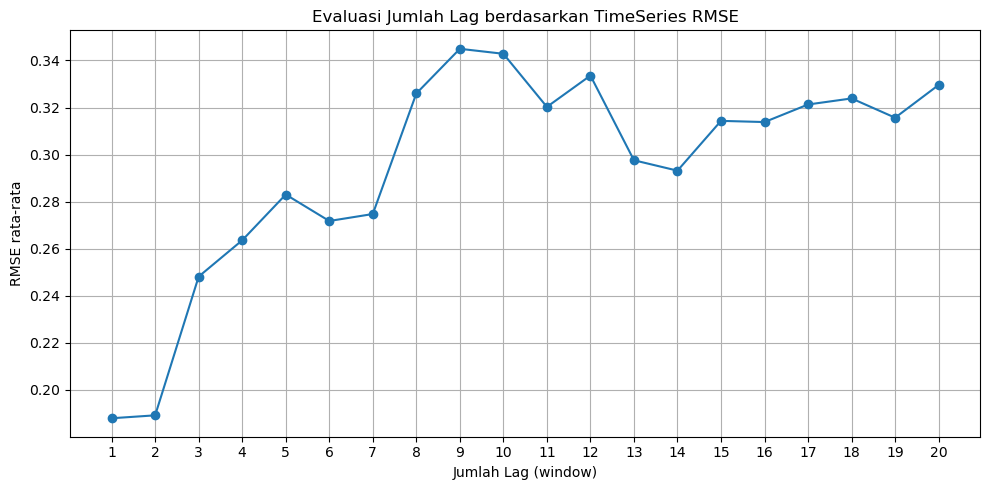

Best window (lag): 1


In [4]:
# 1. Preprocessing
df_clean = preprocess_data(df)
df_clean = add_technical_indicators(df_clean)
df_clean = remove_outliers_iqr(df_clean, ['Close', 'Open', 'High', 'Low', 'Volume'])

# 2. Setup fitur & target
target_columns = ['Close']
feature_columns = ['Open', 'High', 'Low','MA_5', 'MA_10', 'EMA_12', 'EMA_26', 'MACD', 'Momentum', 'Volatility_5', 'Price_Range', 'RSI']

# 3. Cari window lag optimal
results = grid_search_best_lag(df_clean, target_columns, feature_columns)
plot_grid_results(results)
best_window = min(results, key=lambda x: x[1])[0]
print(f'Best window (lag): {best_window}')

In [5]:
# 4. Dataset machine learning
df_ml = create_multivariate_lag_features(df_clean, target_columns, feature_columns, best_window)
x = df_ml.drop(columns=target_columns)
y = df_ml[target_columns]

In [6]:
# 5. Scaling (train full)
scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()
x_scaled = scaler_x.fit_transform(x)
y_scaled = scaler_y.fit_transform(y)

In [7]:
# 6. Train model multioutput
model = MultiOutputRegressor(XGBRegressor(
    objective='reg:squarederror',
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
))
model.fit(x_scaled, y_scaled)

MultiOutputRegressor(estimator=XGBRegressor(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=0.8, device=None,
                                            early_stopping_rounds=None,
                                            enable_categorical=False,
                                            eval_metric=None,
                                            feature_types=None,
                                            feature_weights=None, gamma=None,
                                            grow_policy=None,
                                            importance_type=None,
                                            interaction_constraints=None,
                                            learning_rate=0.1, max_bin=None,
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=5,
                                            max_leaves=None,
                                            min_child_weight=None, missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=100, n_jobs=None,
                                            num_parallel_tree=None, ...))

In [8]:
# 7. Save pipeline (model + scaler)
save_pipeline(model, scaler_x, scaler_y)

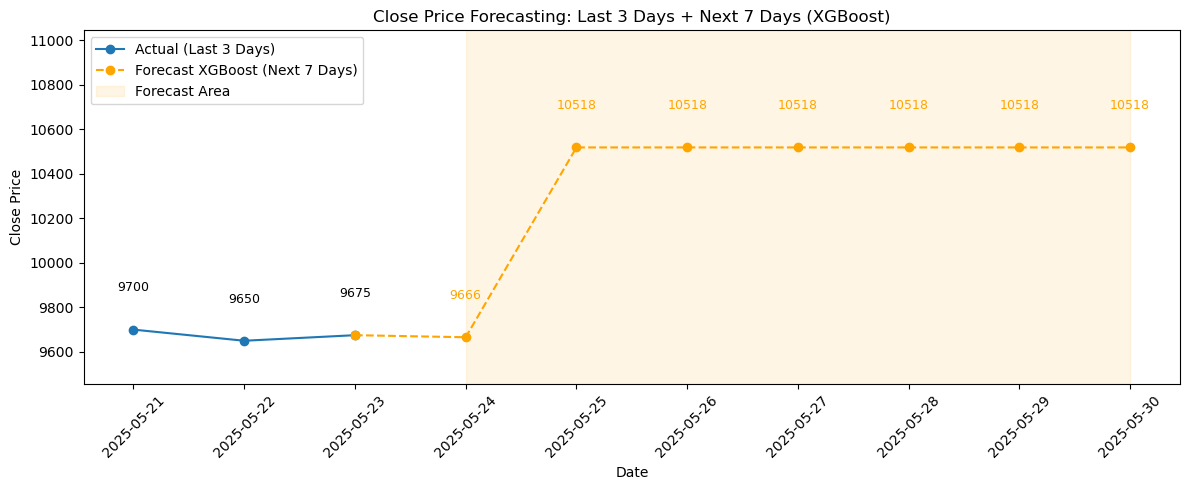

In [9]:
# 8. Forecast ke depan
forecast = predict_stock_pipeline(df_clean, model, scaler_x, scaler_y, target_columns, feature_columns, best_window, n_future=7)

# 9. Visualisasi prediksi
visualize_forecast(df_clean, forecast, n_future=7, last_n_days=3, model_label="XGBoost")

In [10]:
# 10. Feature Importance
# plot_feature_importance(model, x.columns.tolist(), target_columns)

In [11]:
# 11. Evaluasi di Training Set
y_pred = model.predict(x_scaled)
y_pred_inv = scaler_y.inverse_transform(y_pred)
y_true_inv = scaler_y.inverse_transform(y_scaled)
for i, col in enumerate(target_columns):
    mape = mean_absolute_percentage_error(y_true_inv[:, i], y_pred_inv[:, i])
    r2 = r2_score(y_true_inv[:, i], y_pred_inv[:, i])
    print(f"[Train] {col} - MAPE: {mape:.2%}, R²: {r2:.3f}")

[Train] Close - MAPE: 0.15%, R²: 0.999


In [12]:
# 12. Evaluasi di Test Set (7 hari terakhir)
df_test = df_clean[-(best_window + 7):]
df_test_ml = create_multivariate_lag_features(df_test, target_columns, feature_columns, best_window)
x_test = df_test_ml.drop(columns=target_columns)
y_test = df_test_ml[target_columns]
x_test_scaled = scaler_x.transform(x_test)
y_test_scaled = scaler_y.transform(y_test)
y_test_pred_scaled = model.predict(x_test_scaled)
y_test_pred = scaler_y.inverse_transform(y_test_pred_scaled)
y_test_true = scaler_y.inverse_transform(y_test_scaled)
print("\n[Hold-out Test Evaluation]")
for i, col in enumerate(target_columns):
    mape = mean_absolute_percentage_error(y_test_true[:, i], y_test_pred[:, i])
    r2 = r2_score(y_test_true[:, i], y_test_pred[:, i])
    print(f"[Test] {col} - MAPE: {mape:.2%}, R²: {r2:.3f}")


[Hold-out Test Evaluation]
[Test] Close - MAPE: 0.09%, R²: 0.996



== Baseline ARIMA ==


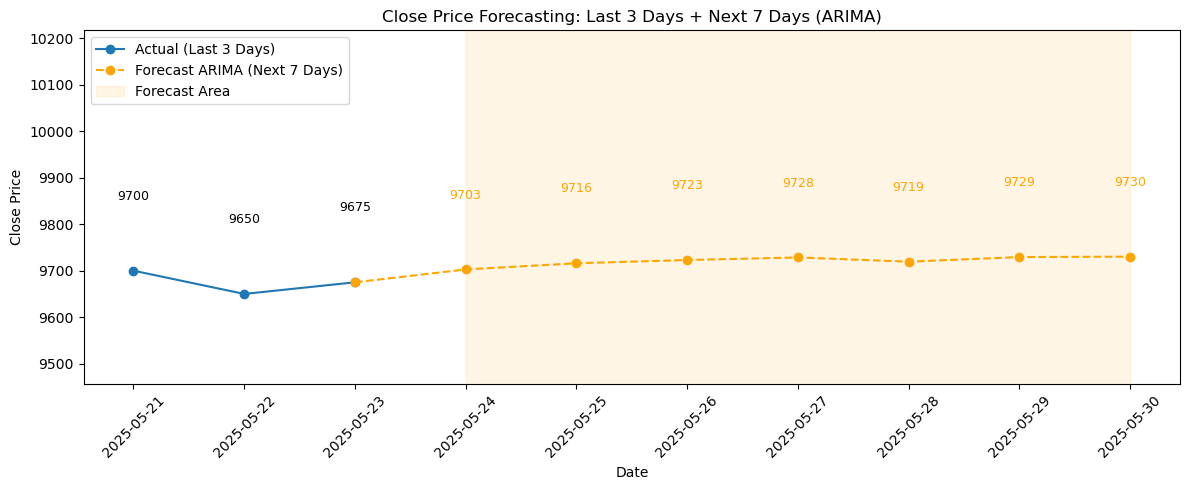


== Baseline Prophet ==


10:58:31 - cmdstanpy - INFO - Chain [1] start processing
10:58:31 - cmdstanpy - INFO - Chain [1] done processing


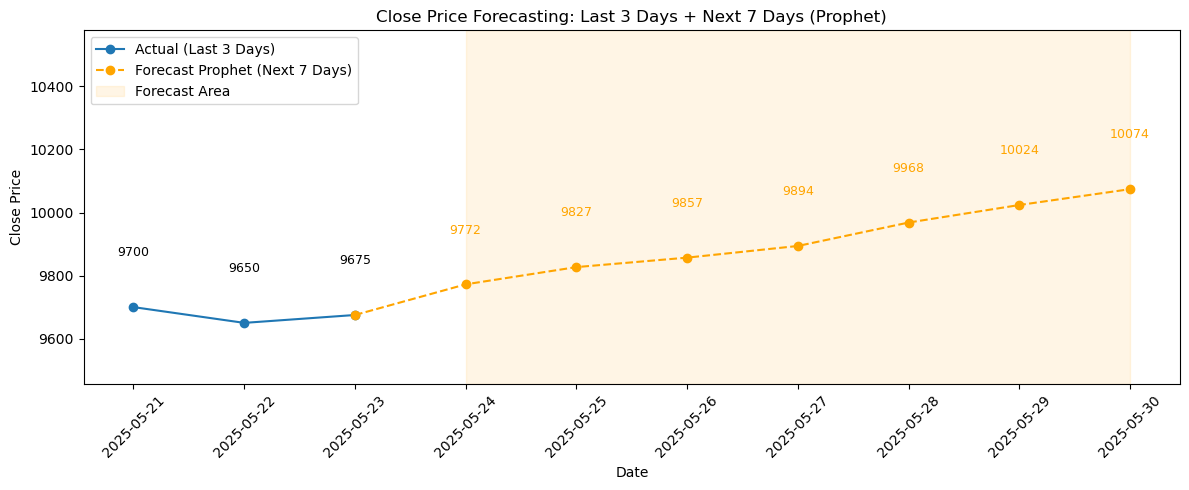

array([ 9772.24773925,  9826.93804612,  9856.95169118,  9893.95698744,
        9968.28433245, 10023.89993425, 10074.18587868])

In [13]:
# 13. Baseline ARIMA & Prophet
print('\n== Baseline ARIMA ==')
forecast_arima(df_clean, n_future=7, last_n_days=3)
print('\n== Baseline Prophet ==')
forecast_prophet(df_clean, n_future=7, last_n_days=3)